# bcpnm tutorial 1: the seven-step workflow

This notebook follows Section 6 of the tutorial paper. We model a small depression–anxiety
comorbidity network with Boolean nodes, simulate a transient stressor, find attractors,
compare update schemes, test interventions, and validate and report the model.
Run the cells in order; every result is reproducible.

In [1]:
import pathlib
import numpy as np
import matplotlib.pyplot as plt
import bcpnm as bc
from bcpnm import visualization as viz

# locate the repository root whether the notebook runs from examples/notebooks or the root
ROOT = pathlib.Path.cwd().resolve()
while not (ROOT / "examples").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
EX = ROOT / "examples"
print("bcpnm", bc.__version__)

bcpnm 0.1.0


## Steps 1–2: nodes and state spaces

Each node is a symptom (or the stressor), with two states: absent (0) and present (1). The
`construct` field documents what the node means; it is copied into the model report.

In [2]:
g = bc.PNMGraph("comorbidity", meta={"domain": "depression-anxiety comorbidity"})
B = bc.StateSpace.boolean("absent", "present")
constructs = {"Stressor": "acute life stressor (context)", "Worry": "excessive worry",
              "Insomnia": "sleep problems", "Fatigue": "fatigue / loss of energy",
              "Concentration": "concentration problems", "Mood": "depressed mood"}
for name, construct in constructs.items():
    g.add_node(name, B, construct=construct)
B

StateSpace(0=absent, 1=present)

## Step 3: rules

Rules are logical statements. Try changing one (for example, make concentration problems
depend on fatigue alone) and re-run the notebook to see how the conclusions change.

PNMGraph 'comorbidity': 6 nodes, 11 directed edges, 64 configurations
  Stressor       states=(0, 1)  rule=ClampRule()
  Worry          states=(0, 1)  rule=BooleanRule(Stressor, Worry, Insomnia)
  Insomnia       states=(0, 1)  rule=BooleanRule(Worry, Mood)
  Fatigue        states=(0, 1)  rule=BooleanRule(Insomnia)
  Concentration  states=(0, 1)  rule=BooleanRule(Fatigue, Worry, Mood)
  Mood           states=(0, 1)  rule=BooleanRule(Fatigue, Concentration)


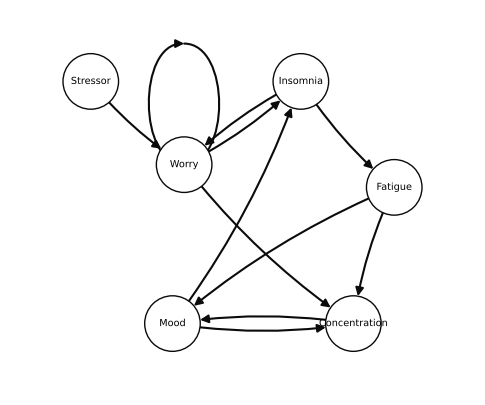

In [3]:
g.set_rule("Stressor", bc.ClampRule(0))
g.set_rule("Worry", bc.BooleanRule("Stressor or (Worry and Insomnia)"))
g.set_rule("Insomnia", bc.OR("Worry", "Mood"))
g.set_rule("Fatigue", bc.BooleanRule("Insomnia"))
g.set_rule("Concentration", bc.BooleanRule("Fatigue and (Worry or Mood)"))
g.set_rule("Mood", bc.AND("Fatigue", "Concentration"))
g.validate()
print(g.summary())
pos = {"Stressor": (-1.3, 1.0), "Worry": (-0.5, 0.45), "Insomnia": (0.5, 1.0), "Fatigue": (1.3, 0.3),
       "Concentration": (0.95, -0.6), "Mood": (-0.6, -0.6)}
viz.plot_network(g, pos=pos, node_size=1600, font_size=7);

## Step 4: simulate a transient stressor

`Intervention` switches a perturbation on for a time window. Here the stressor is present
during steps 2–4 only.

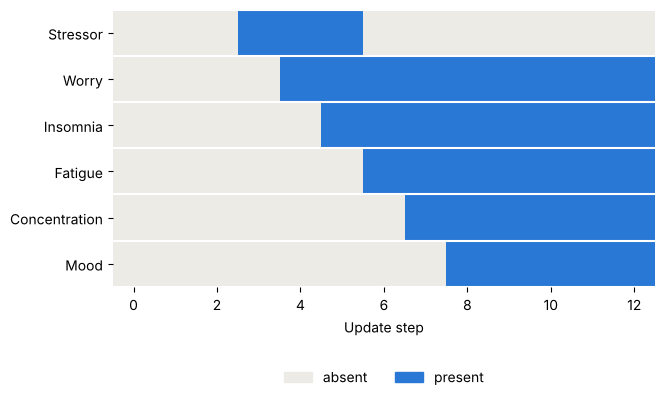

In [4]:
pulse = bc.Intervention(bc.Clamp("Stressor", 1), start=2, end=5, name="stressor")
tr = bc.simulate(g, x0=np.zeros(6), steps=12, scheme="synchronous", interventions=[pulse])
viz.plot_trajectory(tr, labels={0: "absent", 1: "present"});

## Step 5: attractors and long-run behavior

We compare synchronous and asynchronous updating, then add 2% random perturbation to get a
probabilistic Boolean network and compute its exact stationary distribution.

In [5]:
regimes = {(0, 0, 0, 0, 0, 0): "healthy", (0, 1, 1, 1, 1, 1): "comorbid",
           (0, 0, 1, 1, 1, 1): "depressive", (0, 1, 1, 1, 1, 0): "anxious"}
name_of = lambda S: regimes.get(tuple(int(v) for v in S[0]), "other")
sync = bc.find_attractors(g, scheme="synchronous").label_by(name_of)
asyn = bc.find_attractors(g, scheme="asynchronous").label_by(name_of)
print(sync.summary()); print(asyn.summary())
sync.table()

3 attractor(s) [synchronous, exhaustive, 64 states]
  A0 'comorbid': fixed point (length 1), basin 50.0%  [0 1 1 1 1 1]
  A1 'healthy': fixed point (length 1), basin 48.4%  [0 0 0 0 0 0]
  A2 'depressive': fixed point (length 1), basin 1.6%  [0 0 1 1 1 1]
3 attractor(s) [asynchronous, exhaustive, 64 states]
  A0 'comorbid': fixed point (length 1), basin 25.0%  [0 1 1 1 1 1]
  A1 'healthy': fixed point (length 1), basin 7.8%  [0 0 0 0 0 0]
  A2 'depressive': fixed point (length 1), basin 1.6%  [0 0 1 1 1 1]


,attractor,label,kind,length,basin,basin_fraction,weak_basin,state
0,0,comorbid,fixed point,1,32,0.5000,None,0 1 1 1 1 1
1,1,healthy,fixed point,1,31,0.4844,None,0 0 0 0 0 0
2,2,depressive,fixed point,1,1,0.0156,None,0 0 1 1 1 1


synchronous P(Mood present) = 0.029


asynchronous P(Mood present) = 0.412


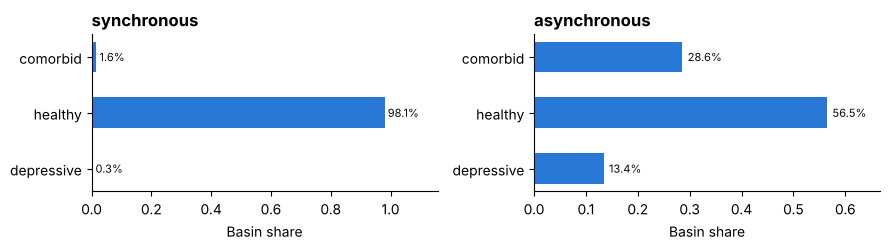

In [6]:
gn = g.copy()
for n in g.names[1:]:
    gn.set_rule(n, bc.NoisyRule(g.rules[n], 0.02))
fig, axs = plt.subplots(1, 2, figsize=(9, 2.6))
for ax, scheme in zip(axs, ("synchronous", "asynchronous")):
    st = bc.stationary_distribution(gn, scheme=scheme)
    qa = bc.quasi_attractors(gn, st, scheme=scheme).label_by(name_of)
    viz.plot_basins(qa, ax=ax, title=scheme)
    print(scheme, "P(Mood present) =", round(st.marginal("Mood")[1], 3))
plt.tight_layout()

## Step 6: interventions

Clamp one symptom at "absent" and see which attractors remain.

In [7]:
for node in ("Worry", "Insomnia", "Mood"):
    after = bc.find_attractors(bc.Clamp(node, 0).apply(g)).label_by(name_of)
    print(bc.compare_attractors(sync, after).assign(intervention=f"suppress {node}").to_string(index=False))
    print()

 attractor   before   after    change   intervention
  comorbid 0.500000 0.00000 -0.500000 suppress Worry
   healthy 0.484375 0.90625  0.421875 suppress Worry
depressive 0.015625 0.09375  0.078125 suppress Worry

 attractor   before  after    change      intervention
  comorbid 0.500000    0.0 -0.500000 suppress Insomnia
   healthy 0.484375    1.0  0.515625 suppress Insomnia
depressive 0.015625    0.0 -0.015625 suppress Insomnia

 attractor   before  after    change  intervention
  comorbid 0.500000    0.0 -0.500000 suppress Mood
   healthy 0.484375    0.5  0.015625 suppress Mood
depressive 0.015625    0.0 -0.015625 suppress Mood
   anxious 0.000000    0.5  0.500000 suppress Mood



## Step 7: validation, sensitivity and reporting

canalizing inputs of Insomnia: [('Worry', 1, 1), ('Mood', 1, 1)]
average sensitivity: {'Stressor': 0.0, 'Worry': 1.248, 'Insomnia': 1.016, 'Fatigue': 1.0, 'Concentration': 1.255, 'Mood': 0.998, 'mean': 0.919}


,source,target,expected,effect,implied,agree
0,Worry,Insomnia,1,0.4911,1,True
1,Insomnia,Fatigue,1,1.0000,1,True
2,Fatigue,Mood,1,0.5010,1,True
3,Mood,Insomnia,1,0.5151,1,True


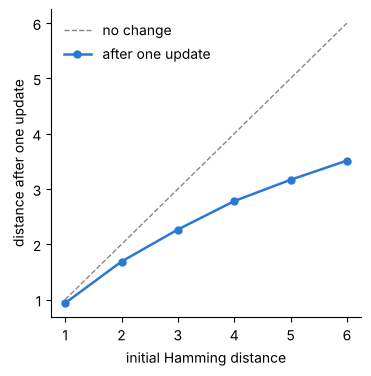

In [8]:
print("canalizing inputs of Insomnia:", bc.canalizing_inputs(g, "Insomnia"))
print("average sensitivity:", {k: round(v, 3) for k, v in bc.average_sensitivity(g, seed=1).items()})
curve = bc.derrida_curve(g, samples=4000, seed=1)
viz.plot_derrida(curve)
expected = [("Worry", "Insomnia", +1), ("Insomnia", "Fatigue", +1), ("Fatigue", "Mood", +1), ("Mood", "Insomnia", +1)]
bc.expert_consistency(g, expected, seed=1)

In [9]:
out = ROOT / "outputs"; out.mkdir(exist_ok=True)
bc.write_report(out / "comorbidity_report.md", g, sections={"Attractors": bc.results_text(sync)})
bc.save_config(bc.graph_to_config(g), out / "comorbidity.yaml")
print(bc.methods_text(g, scheme="synchronous"))
bc.checklist().head(8)

We specified a probabilistic network model ('comorbidity') with 6 nodes, each taking 2 ordered states, and 11 directed influences (64 possible configurations). Update rules were of type BooleanRule, ClampRule. Nodes were updated synchronously (all nodes updated at each step). Analyses used bcpnm 0.1.0 (Python 3.13.16).


,section,item,report,adapted_from
0,Purpose,1. Research question,"State the question, the target system and whet...",STROBE 2-3; ODD 1
1,Purpose,2. Level of analysis,Say whether nodes are persons (interpersonal n...,STROBE 5-6; ODD 2
2,Specification,3. Nodes,"List every node with its construct, operationa...",STROBE 7-8; ODD 2
3,Specification,4. State spaces,"Give each node's admissible states and labels,...",STROBE 11; ODD 2
4,Specification,5. Update rules,"Report every rule (logical expression, thresho...",ODD 7
5,Specification,6. Parameters,"Tabulate all parameter values, their scale and...",ODD 6-7
6,Specification,7. Update scheme and time,"State the update scheme (synchronous, asynchro...",ODD 3
7,Specification,8. Initial conditions,Describe how initial states were set (observed...,ODD 5


**Exercises.** (1) Replace synchronous by sequential updating in Step 4. (2) Change the noise
level in Step 5 from 0.02 to 0.005 and 0.05: which conclusions are robust? (3) Add a node
"Support" that blocks the effect of worry on insomnia and repeat Step 6.